# 13.9.2 문항 8 조건 변경 참고 실습

기준과 현재의 정규분포 합성 표본 각 3000개를 사용합니다. 평균·표준편차 차이가 분포 지표에 주는 영향을 살핍니다. 뒤의 선형 계산은 학습한 모델의 예측이 아닙니다.

선정 이유: 기준 프로그램의 조건 하나를 바꾼 참고 구현입니다. 코드 차이와 실제 결과를 대조하고 테스트 결과로 가장 좋은 조건을 반복 선택하지 않습니다. 원인 해석과 보고서는 독자가 작성합니다.

커널을 다시 시작한 뒤 각 셀을 위에서 아래로 실행합니다. 코드에는 가져오기와 함수 정의도 포함되어 있습니다.

## 셀 1 라이브러리 가져오기

가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.

In [1]:
# 가져오기(Import) 문장으로 경로 객체(Path)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from pathlib import Path

# 가져오기(Import) 문장으로 자바스크립트 객체 표기법(JavaScript Object Notation, JSON) 도구를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import json

# 가져오기(Import) 문장으로 수치 배열 도구 넘파이(Numerical Python, NumPy)의 별칭 np를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import numpy as np

# 가져오기(Import) 문장으로 자료 표 도구 판다스(pandas)의 별칭 pd를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import pandas as pd

# 가져오기(Import) 문장으로 맷플롯립 파이플롯(Matplotlib Pyplot)의 별칭 plt를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
import matplotlib.pyplot as plt

# 가져오기(Import) 문장으로 셀 출력 표시 함수(display), 이미지 표시 객체(IPython Image)를 연결합니다. 이 셀에서는 자료를 학습하지 않습니다.
from IPython.display import display, Image as NotebookImage

## 셀 2 입력·계산·출력 확인

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.

검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.

In [2]:
# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.rcParams.update({"font.family":"DejaVu Sans","font.size":11,"svg.fonttype":"none","axes.prop_cycle":plt.cycler(color=["black","0.45","0.7"]),"figure.figsize":(7,4.2)})

# 변수 HERE를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
HERE=Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()

# 변수 CHAPTER를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
CHAPTER=HERE if (HERE/"data").exists() else HERE.parent

# 입력 폴더(Data Directory, DATA)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
DATA=CHAPTER/"data"

# 출력 폴더(Output Directory, OUT)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
OUT=HERE/"results"/"q08_parameter_change"

# 앞 셀의 값을 사용해 OUT.mkdir(parents=True,exist_ok=True) 동작을 수행합니다. 코드에 쓰인 괄호·인자·들여쓰기를 유지합니다.
OUT.mkdir(parents=True,exist_ok=True)

# 검증 조건(Assertion)을 확인합니다. 거짓이면 셀을 중단하며 실패를 성공한 결과로 바꾸지 않습니다.
assert DATA.exists(), f"장별 data 폴더를 함께 내려받으세요: {DATA}"

## 셀 3 함수와 모듈 정의

그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.

In [3]:
# 그림 저장 함수(figure)를 정의합니다. 실제 현재 그림을 벡터 형식과 300dpi 이미지로 저장하고 노트북에 표시합니다. 함수 정의와 뒤의 실제 호출을 구분합니다.
def figure(out,name):
    plt.tight_layout()
    plt.savefig(out/(name+".svg"),facecolor="white")
    plt.savefig(out/(name+".png"),dpi=300,facecolor="white")
    if "get_ipython" in globals():display(NotebookImage(filename=str(out/(name+".png"))))
    plt.close()

## 셀 4 함수와 모듈 정의

결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.

In [4]:
# 결과 기록 함수(report)를 정의합니다. 계산된 지표만 JSON과 문자 출력에 기록하며 비유한 수치를 성공값으로 바꾸지 않습니다.
def report(out,name,metrics):
    text=json.dumps(metrics,ensure_ascii=False,indent=2,allow_nan=False)
    (out/(name+".json")).write_text(text,encoding="utf-8")
    print(text)

## 셀 5 함수와 모듈 정의

population_stability_index의 입력·처리·반환을 정의합니다. 들여쓴 문장은 함수 또는 순전파가 호출될 때 실행됩니다. 아래 코드를 따라 조건·반복·종료 경로를 확인합니다.

In [5]:
# population_stability_index의 입력·처리·반환을 정의합니다. 들여쓴 문장은 함수 또는 순전파가 호출될 때 실행됩니다. 아래 코드를 따라 조건·반복·종료 경로를 확인합니다.
def population_stability_index(reference, current, bins=10, eps=1e-6):
    edges = np.quantile(reference, np.linspace(0, 1, bins + 1))
    edges[0], edges[-1] = -np.inf, np.inf
    ref_counts, _ = np.histogram(reference, bins=edges)
    cur_counts, _ = np.histogram(current, bins=edges)
    ref_ratio = np.maximum(ref_counts / len(reference), eps)
    cur_ratio = np.maximum(cur_counts / len(current), eps)
    return np.sum((cur_ratio - ref_ratio) * np.log(cur_ratio / ref_ratio))

## 셀 6 입력·계산·출력 확인

변수 rng를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 reference를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 current를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

모집단 안정성 지수(Population Stability Index, psi)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 status를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 val1·변수 val2를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

변수 result를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.

실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.

PSI: 0.0225
Drift Status: 정상
입력 피처: (5.0, 2.5)
교육용 선형 계산 결과: 12.50


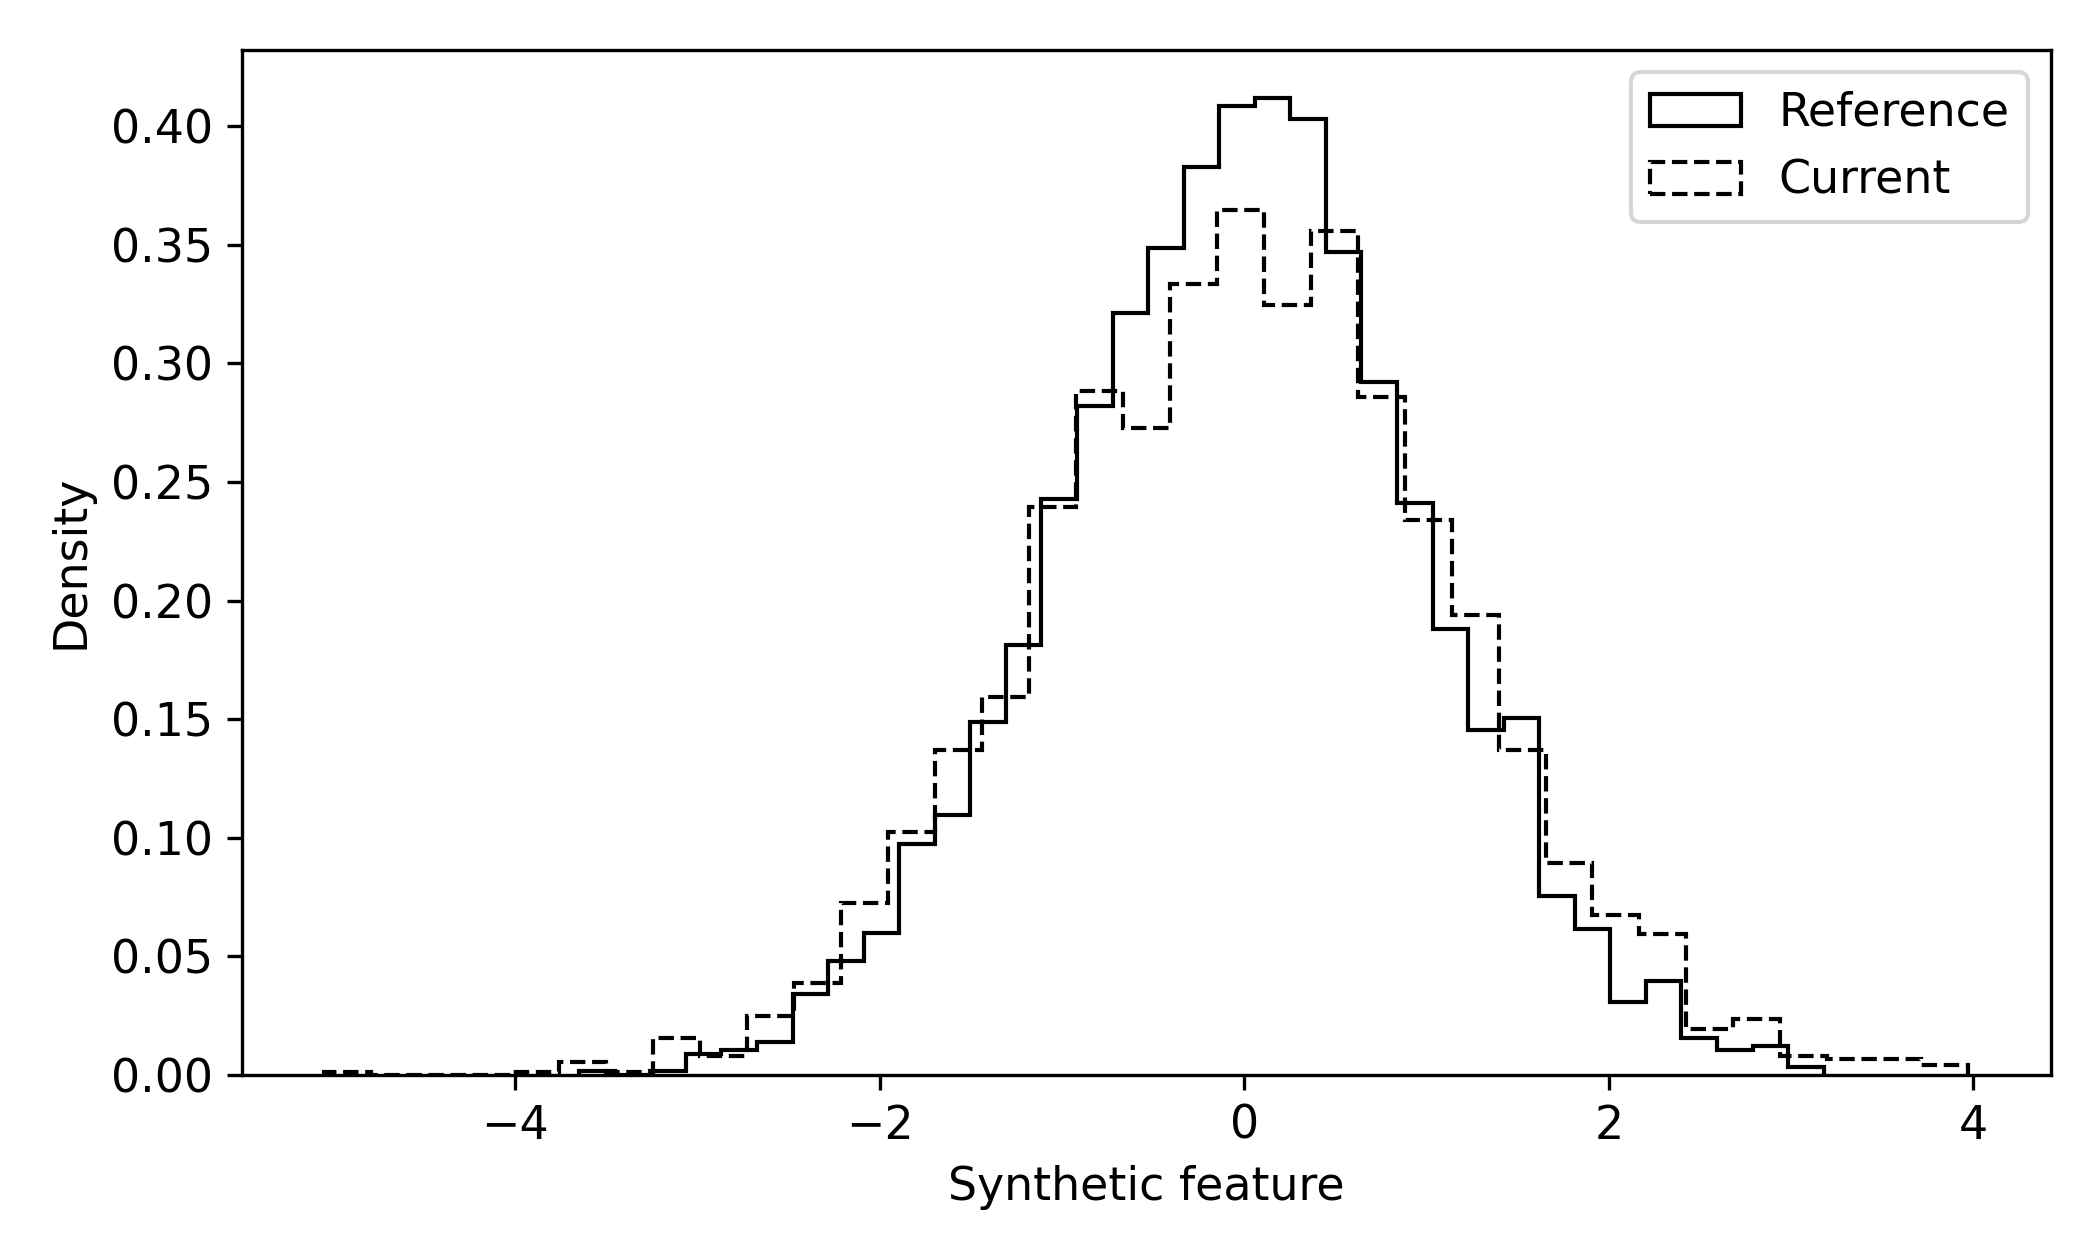

In [6]:
# 변수 rng를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
rng = np.random.default_rng(42)

# 변수 reference를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
reference = rng.normal(0.0, 1.0, 3000)

# 변수 current를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
current = rng.normal(0.0, 1.15, 3000)

# 모집단 안정성 지수(Population Stability Index, psi)를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
psi = population_stability_index(reference, current)

# 변수 status를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
status = "정상" if psi < 0.10 else "주의" if psi < 0.25 else "재학습 검토"

# 변수 val1·변수 val2를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
val1, val2 = 5.0, 2.5

# 변수 result를 오른쪽 식으로 계산해 다음 단계에서 사용합니다. 값과 형태(Shape)를 구분하고 앞 셀의 입력이 준비되어 있는지 확인합니다.
result = val1 * 1.5 + val2 * 2.0

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"PSI: {psi:.4f}")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"Drift Status: {status}")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"입력 피처: ({val1:.1f}, {val2:.1f})")

# 문자 출력(Print)으로 현재 결과를 확인합니다. 반올림된 표시값과 내부 배열의 정밀도는 다를 수 있습니다.
print(f"교육용 선형 계산 결과: {result:.2f}")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.hist(reference,bins=35,density=True,histtype="step",color="black",label="Reference")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.hist(current,bins=35,density=True,histtype="step",color="black",linestyle="--",label="Current")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.xlabel("Synthetic feature")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.ylabel("Density")

# 그림의 축·제목·범례·표시 범위를 설정합니다. 표시 범위가 계산에 사용한 관측 수를 바꾸는 것은 아닙니다.
plt.legend()

# 실제 계산한 그림을 저장하고 표시합니다. 축·기호·범례의 의미는 이 실습의 결과 해설과 대조합니다.
figure(OUT,"drift_distributions")

## 셀 7 입력·계산·출력 확인

실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.

In [7]:
# 실제 계산한 수치를 결과 파일과 셀 출력에 기록합니다. 다른 데이터나 미실행 모델의 성능으로 해석하지 않습니다.
report(OUT,"summary",{"PSI":float(psi),"status":status,"educational_linear_result":result,"trained_model":False})

{
  "PSI": 0.022513466634676807,
  "status": "정상",
  "educational_linear_result": 12.5,
  "trained_model": false
}


## 그림과 결과 해석

기준 프로그램의 조건 하나를 바꾼 참고 구현입니다. 코드 차이와 실제 결과를 대조하고 테스트 결과로 가장 좋은 조건을 반복 선택하지 않습니다. 원인 해석과 보고서는 독자가 작성합니다. 기준·현재 히스토그램을 같은 축에서 비교합니다. 표시용 구간과 안정성 지수의 기준 분위수 구간은 다르며 임계값은 교육용 규칙입니다.